# 07 - Model Comparison and Best Model Selection

In [1]:
import sys, warnings
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve
from src import config as C
from src.select_best_model import load_results, select_best, MODEL_NAMES
table = load_results()
table.drop(columns="params").round(3)

,model,val_roc_auc,val_pr_auc,val_f2,test_roc_auc,test_pr_auc,test_precision,test_recall,test_specificity,test_f1,test_f2,test_balanced_accuracy,threshold
0,dummy,0.500,0.022,0.000,0.500,0.020,0.000,0.000,1.000,0.000,0.000,0.500,0.500
1,logistic_regression,0.690,0.095,0.251,0.721,0.094,0.110,0.349,0.942,0.167,0.243,0.645,0.651
2,decision_tree,0.714,0.083,0.261,0.735,0.083,0.148,0.356,0.958,0.209,0.278,0.657,0.843
3,random_forest,0.765,0.102,0.266,0.783,0.102,0.142,0.385,0.952,0.207,0.287,0.669,0.607
4,svm,0.740,0.082,0.237,0.755,0.079,0.090,0.380,0.921,0.146,0.231,0.651,0.435


## Metric comparison (test set)

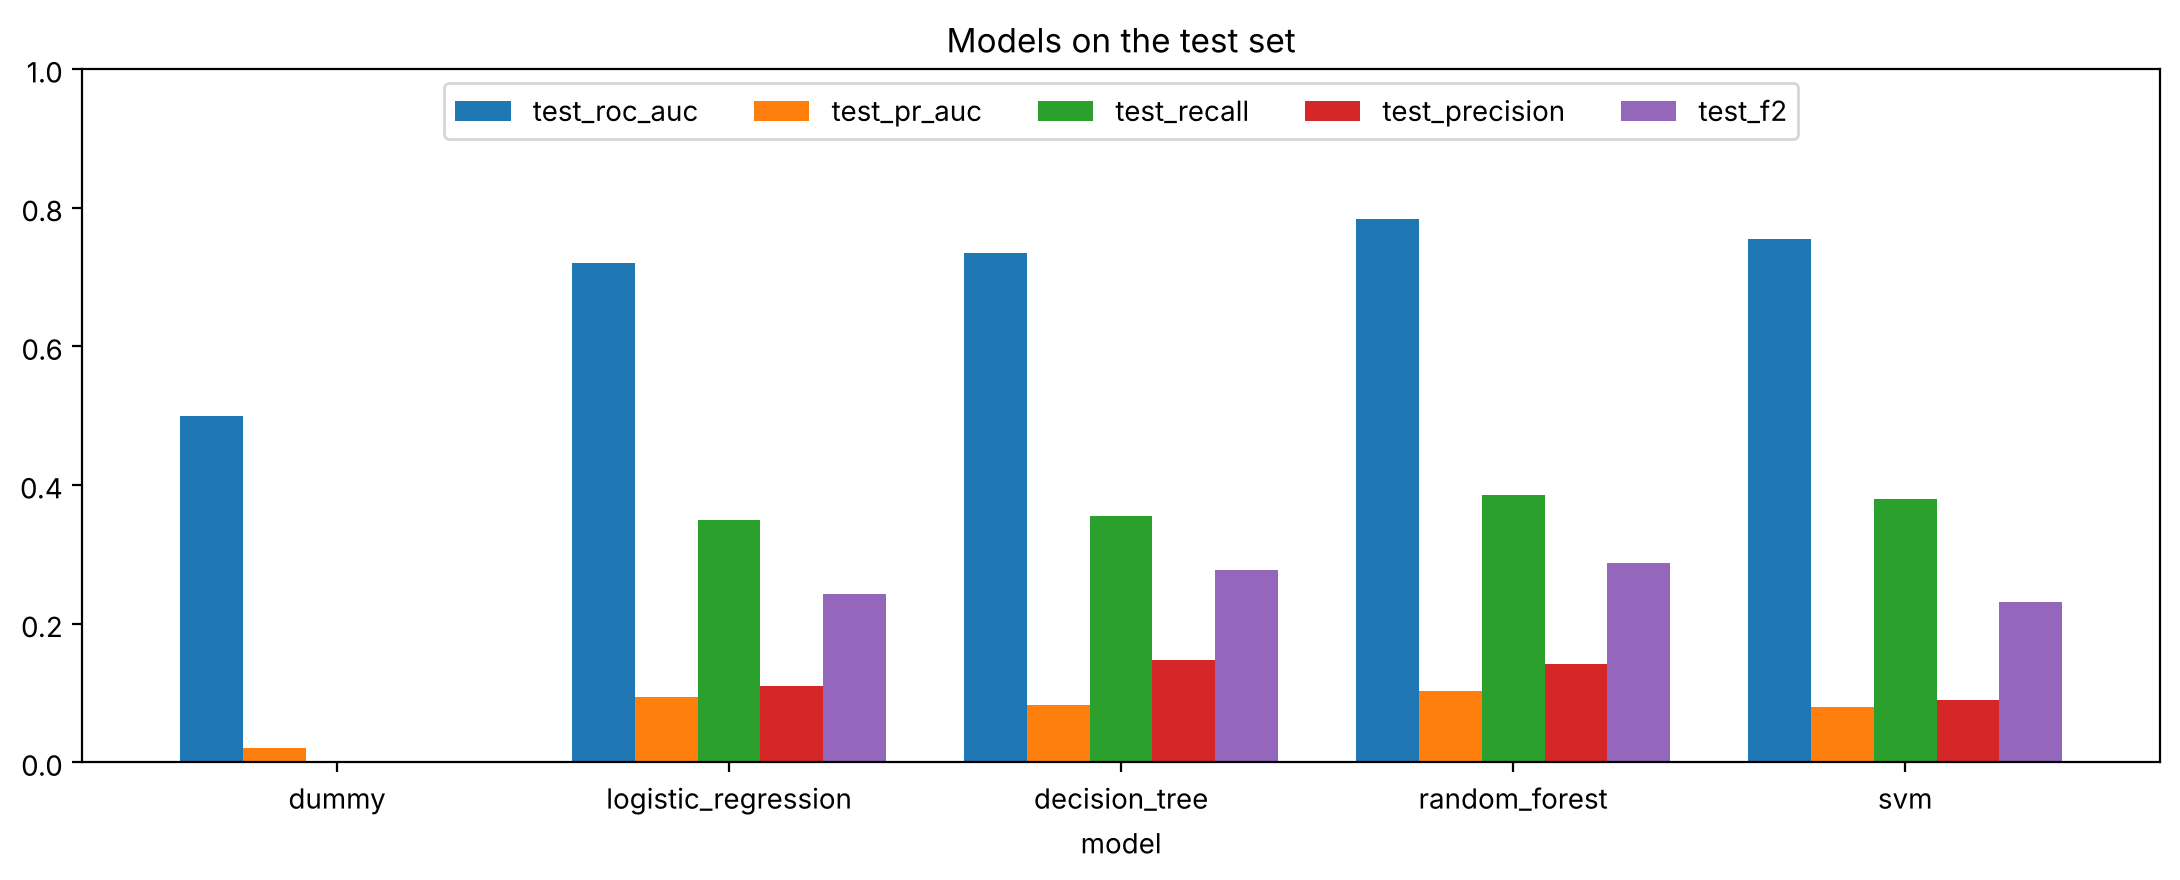

In [2]:
metrics = ["test_roc_auc", "test_pr_auc", "test_recall", "test_precision", "test_f2"]
ax = table.set_index("model")[metrics].plot.bar(figsize=(11, 4.5), rot=0, width=0.8)
ax.set(title="Models on the test set", ylim=(0, 1)); plt.legend(ncol=5, loc="upper center")
plt.tight_layout(); plt.savefig(C.FIG_DIR / "model_comparison_bars.png", dpi=130); plt.show()

## ROC and Precision-Recall curves on the same test set

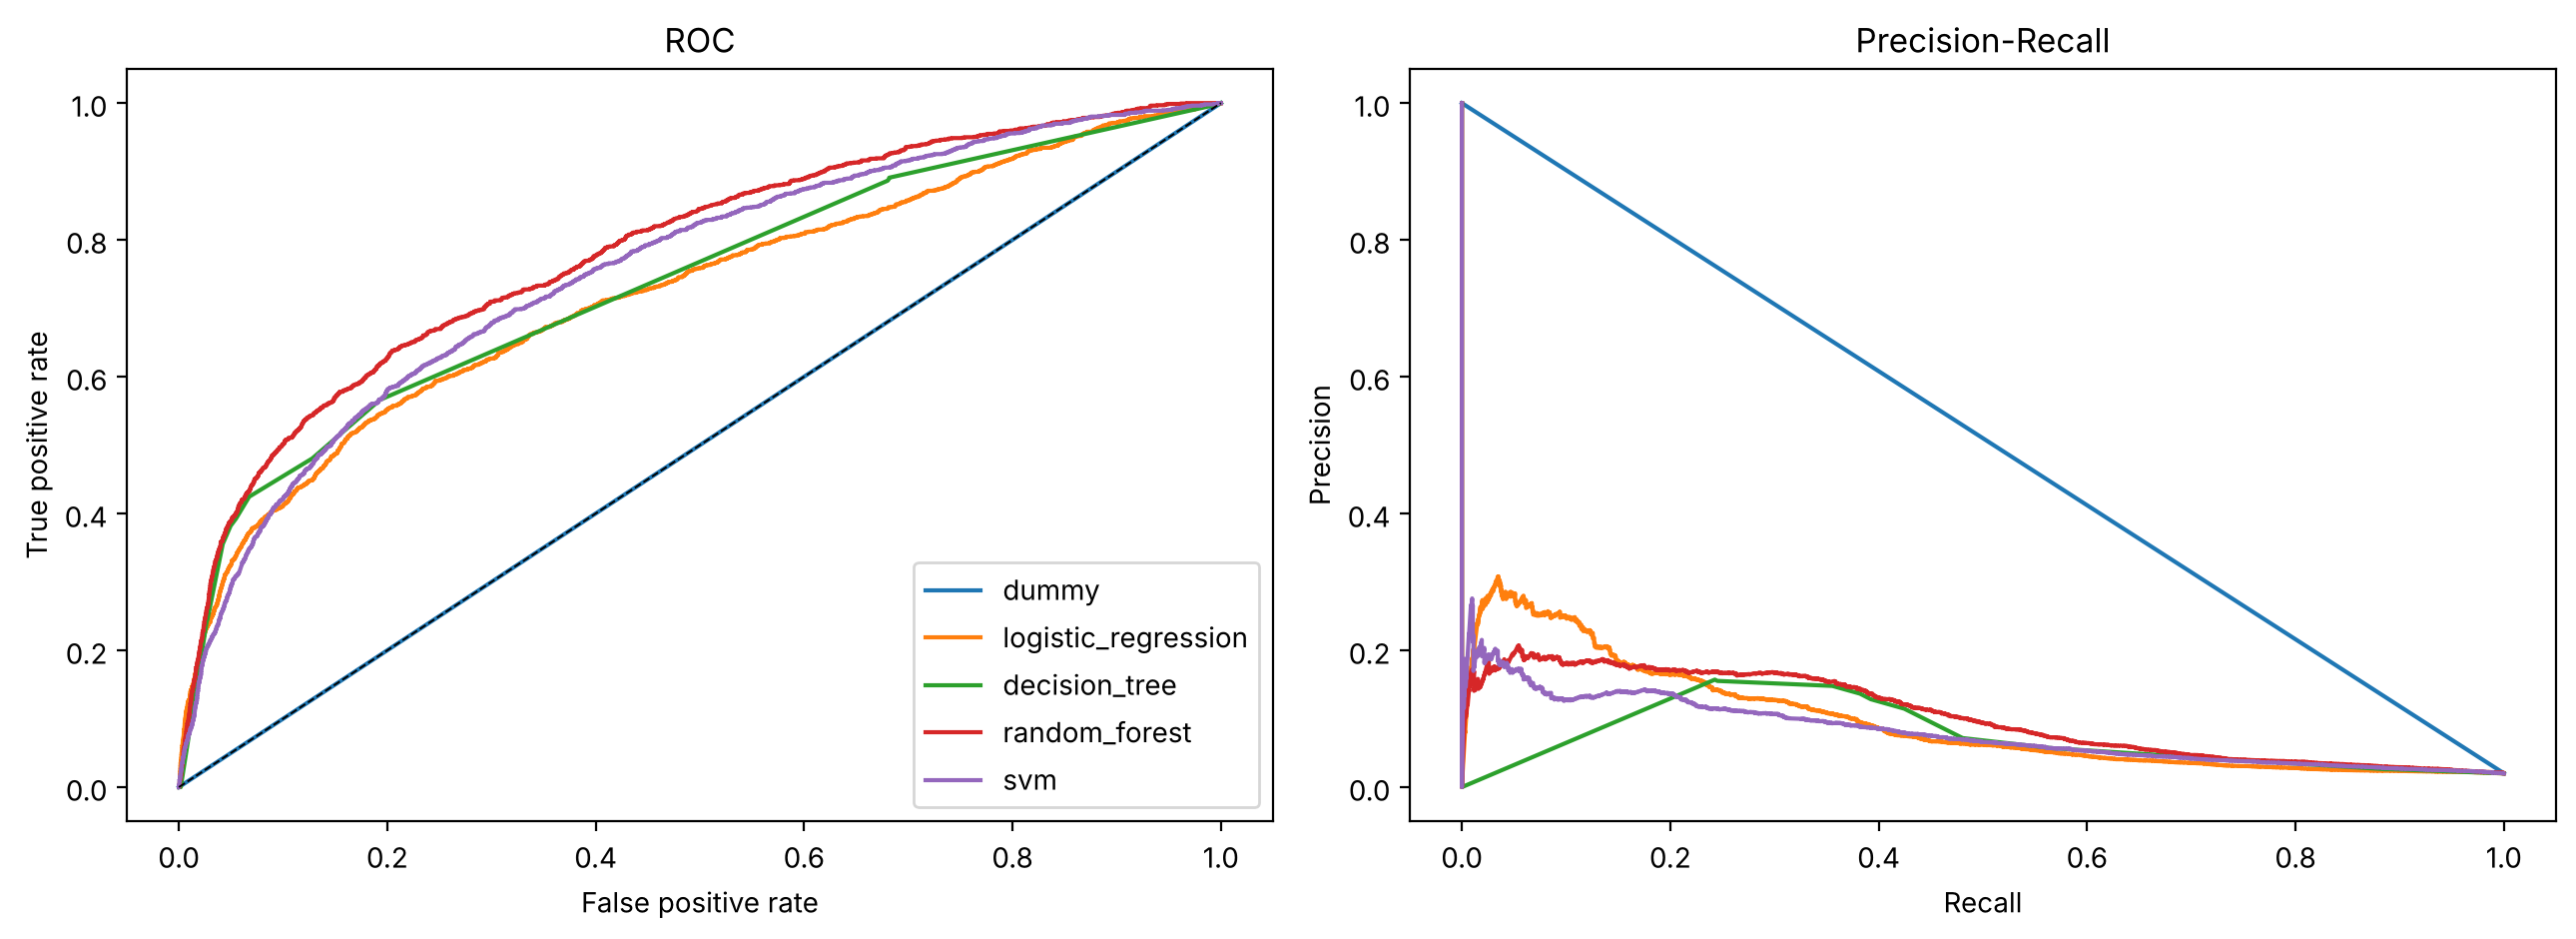

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
for name in MODEL_NAMES:
    d = np.load(C.RESULTS_DIR / f"preds_{name}.npz")
    fpr, tpr, _ = roc_curve(d["y_test"], d["p_test"])
    p, r, _ = precision_recall_curve(d["y_test"], d["p_test"])
    ax[0].plot(fpr, tpr, label=name); ax[1].plot(r, p, label=name)
ax[0].plot([0, 1], [0, 1], "k--", lw=.7)
ax[0].set(title="ROC", xlabel="False positive rate", ylabel="True positive rate")
ax[1].set(title="Precision-Recall", xlabel="Recall", ylabel="Precision")
ax[0].legend(); plt.tight_layout()
plt.savefig(C.FIG_DIR / "model_comparison_curves.png", dpi=130); plt.show()

## Select the best model
Rule: highest average of validation ROC-AUC, PR-AUC and F2 (dummy ignored). The test set is never used to choose. The winner's settings are saved in `models/best_model_config.json`.

In [4]:
bundle = select_best()
print("Selected:", bundle["model_name"], "| settings:", bundle["tuned_params"])

              model  val_roc_auc  val_pr_auc  val_f2  test_roc_auc  test_pr_auc  test_precision  test_recall  test_specificity  test_f1  test_f2  test_balanced_accuracy  threshold  val_score
              dummy        0.500       0.022   0.000         0.500        0.020           0.000        0.000             1.000    0.000    0.000                   0.500      0.500      0.174
logistic_regression        0.690       0.095   0.251         0.721        0.094           0.110        0.349             0.942    0.167    0.243                   0.645      0.651      0.346
      decision_tree        0.714       0.083   0.261         0.735        0.083           0.148        0.356             0.958    0.209    0.278                   0.657      0.843      0.353
      random_forest        0.765       0.102   0.266         0.783        0.102           0.142        0.385             0.952    0.207    0.287                   0.669      0.607      0.377
                svm        0.740       0.082 

## Final pipeline
Train ONLY the selected model with the saved settings and save the single pickle `models/best_model.pkl`.

In [5]:
from src.final_pipeline import train_final
final = train_final()

Saved best_model.pkl: random_forest, threshold 0.607
{'roc_auc': 0.783, 'pr_auc': 0.102, 'threshold': 0.607, 'precision': 0.142, 'recall': 0.385, 'specificity': 0.952, 'f1': 0.207, 'f2': 0.287, 'balanced_accuracy': 0.669}
